# M4 — Initial Insights: DPWH Flood Control Projects (2022–2025)

**Problem statement:** Can publicly available DPWH flood control project data reveal unusual geographic, financial, and contractor-related patterns that may indicate areas requiring further audit or investigation between 2022 and 2025?

**Scope:** Phase 4 (Weeks 13–16), using the cleaned file `data/processed/dpwh_flood_control_analysis_ready.csv`. It follows the M4 pass criteria: 3–5 labelled charts, written interpretation under each, one cautious inference section, and a narrative back to the problem statement.

| Section | Week | Content |
|---|---|---|
| 1 | 13 | Descriptive statistics |
| 2 | 14 | EDA and charts (Charts 1–5) |
| 3 | 15 | Inference with analytical caution |
| 4 | 16 | Insights and narrative |

> Everything below describes **patterns that may merit review**. None of it shows wrongdoing, fraud or corruption.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

# Find the repo root so the notebook runs from /notebooks or the repo root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/processed/dpwh_flood_control_analysis_ready.csv").exists())
FIG = ROOT / "output/figures"; FIG.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(ROOT / "data/processed/dpwh_flood_control_analysis_ready.csv")
COST = "contract_cost_php"
print(df.shape)
df[["project_id","region","province","contractor",COST,"is_high_cost_outlier","cost_zscore_regional"]].head()

(9827, 30)


,project_id,region,province,contractor,contract_cost_php,is_high_cost_outlier,cost_zscore_regional
0,P00526268LZ,Cordillera Administrative Region,Apayao,ASC CONSTRUCTION & CONCRETE PRODUCTS,92692943.80,0,1.2192
1,P00526368LZ,Cordillera Administrative Region,Apayao,ASC CONSTRUCTION & CONCRETE PRODUCTS,47521251.30,0,-0.0466
2,P00526369LZ,Cordillera Administrative Region,Apayao,ASC CONSTRUCTION & CONCRETE PRODUCTS,45942583.67,0,-0.0909
3,P00561270LZ,Cordillera Administrative Region,Apayao,ASC CONSTRUCTION & CONCRETE PRODUCTS,9900000.00,0,-1.1009
4,P00561652LZ,Cordillera Administrative Region,Apayao,ALEPHNORTH PEAK CONSTRUCTION AND DEVELOPMENT CO.,4950000.00,0,-1.2396


## 1. Descriptive statistics (Week 13)

In [2]:
done = pd.to_datetime(df.actualcompletiondate, errors="coerce")
checks = {
    "projects": len(df), "unique project_id": df.project_id.nunique(),
    "regions": df.region.nunique(), "provinces": df.province.nunique(), "contractors": df.contractor.nunique(),
    "zero-cost contracts": int((df[COST] == 0).sum()), "blank municipality": int(df.municipality.isna().sum()),
    "completion range": f"{done.min():%Y-%m-%d} to {done.max():%Y-%m-%d}",
}
display(pd.Series(checks, name="value").to_frame())
display((df[COST] / 1e6).describe().round(1).rename("contract cost (PHP millions)").to_frame())
print("Skewness:", round(df[COST].skew(), 2), "| Total cost (PHP billions):", round(df[COST].sum() / 1e9, 1))
print("Share of total cost held by the costliest 5% of projects:", round(df[COST].nlargest(int(len(df) * .05)).sum() / df[COST].sum(), 3))
display(df.groupby("fundingyear").agg(projects=("project_id", "count"), cost_bn=(COST, lambda s: round(s.sum() / 1e9, 1))).T)
display(df.typeofwork.value_counts().head(5).to_frame("projects"))

,value
projects,9827
unique project_id,9827
regions,16
provinces,84
contractors,2409
zero-cost contracts,0
blank municipality,638
completion range,2022-07-01 to 2025-05-30


,contract cost (PHP millions)
count,9827.0
mean,55.5
std,39.5
min,1.2
25%,24.5
50%,49.0
75%,85.2
max,289.5


Skewness: 1.33 | Total cost (PHP billions): 545.6
Share of total cost held by the costliest 5% of projects: 0.144


fundingyear,2018,2019,2020,2021,2022,2023,2024,2025
projects,7.0,3.0,35.0,592.0,3335.0,3466.0,2354.0,35.0
cost_bn,0.7,0.3,2.3,28.5,164.3,203.4,144.7,1.5


,projects
typeofwork,
Construction of Flood Mitigation Structure,6343
Construction of Slope Protection Structure,739
Construction of Revetment,733
Construction of Drainage Structure,678
Rehabilitation / Major Repair of Flood Control Structure,646


**Interpretation.** The file holds 9,827 completed projects worth about ₱545.6B, with a mean contract of ₱55.5M and a median of ₱49.0M. The right skew (1.33) means a minority of large contracts pulls the mean above the median, and the costliest 5% of projects hold about 14% of total value. Most projects (about 6,300) are flood mitigation structures, and nearly all were funded in 2021–2024, so the analysis is effectively about that window. Data caveats to carry forward: 638 rows with no municipality. The 27 multi-year (MYCA) projects that appear on more than one funding-year row are counted once, with the cost from the row that records it.

## 2. EDA and visualization (Week 14)

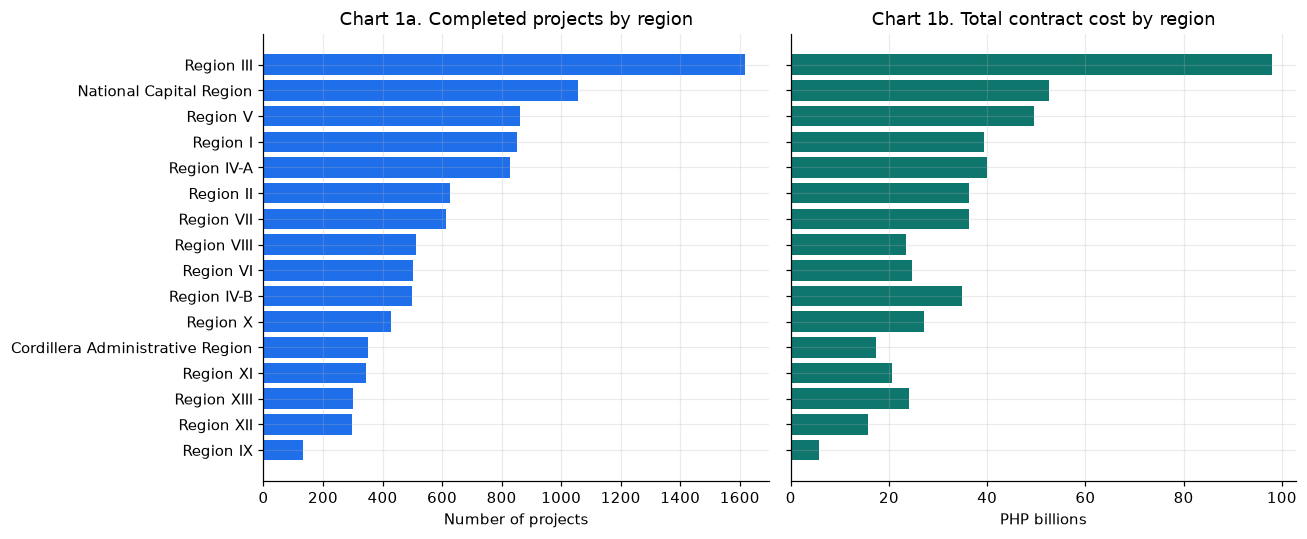

In [3]:
reg = df.groupby("region").agg(projects=("project_id", "count"), cost_bn=(COST, lambda s: s.sum() / 1e9)).sort_values("projects")
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
ax[0].barh(reg.index, reg.projects, color="#1F6FEB"); ax[0].set_title("Chart 1a. Completed projects by region"); ax[0].set_xlabel("Number of projects")
ax[1].barh(reg.index, reg.cost_bn, color="#0F766E"); ax[1].set_title("Chart 1b. Total contract cost by region"); ax[1].set_xlabel("PHP billions")
plt.tight_layout(); plt.savefig(FIG / "chart1_region_projects_cost.png", bbox_inches="tight"); plt.show()

**Chart 1 interpretation.** Region III stands out with 1,617 projects and about ₱98B, nearly double the next region by value, while Region IX has only 132 projects. Cost tracks project count closely, so differences in volume explain most of the regional gap in total value. These are raw totals, not adjusted for population, land area or flood exposure, so the chart shows where the money went, not whether it was proportionate.

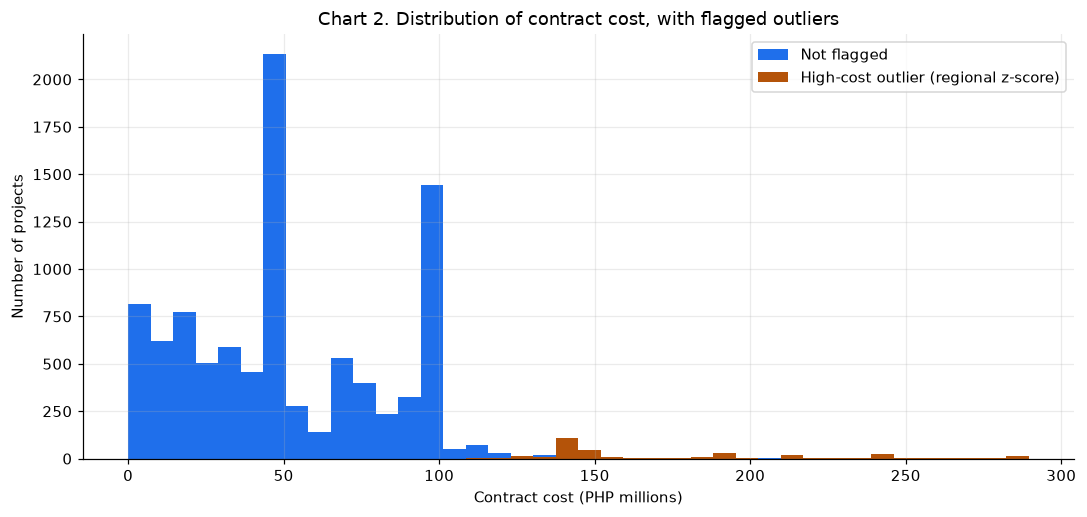

Flagged outliers: 326 (3.3%)


In [4]:
fig, ax = plt.subplots(figsize=(10, 4.8))
bins = np.linspace(0, df[COST].max() / 1e6, 41)
ax.hist(df.loc[df.is_high_cost_outlier == 0, COST] / 1e6, bins=bins, color="#1F6FEB", label="Not flagged")
ax.hist(df.loc[df.is_high_cost_outlier == 1, COST] / 1e6, bins=bins, color="#B45309", label="High-cost outlier (regional z-score)")
ax.set(title="Chart 2. Distribution of contract cost, with flagged outliers", xlabel="Contract cost (PHP millions)", ylabel="Number of projects"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "chart2_cost_distribution.png", bbox_inches="tight"); plt.show()
print("Flagged outliers:", int(df.is_high_cost_outlier.sum()), f"({df.is_high_cost_outlier.mean():.1%})")

**Chart 2 interpretation.** Contract costs are concentrated below ₱100M with a long right tail up to ₱289.5M, and 326 projects (3.3%) are flagged as high-cost outliers. Flags can appear well inside the overall cost range because they are judged against each region’s own average and spread. A flagged project is therefore expensive for its region, which makes it a candidate for review rather than a confirmed anomaly.

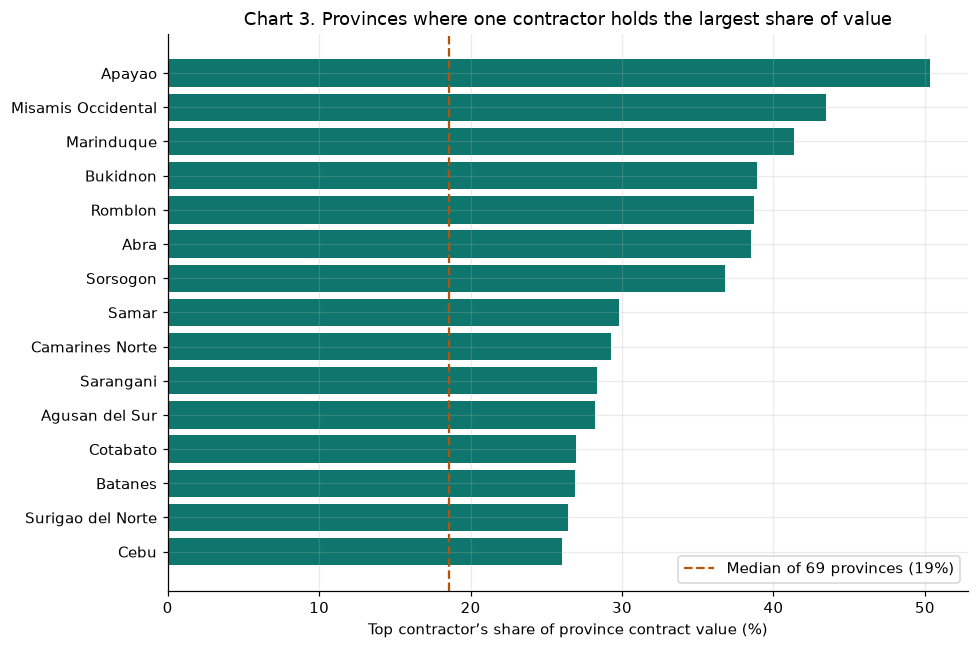

In [5]:
prov = df.groupby("province").apply(lambda g: pd.Series({
    "projects": len(g), "contractors": g.contractor.nunique(),
    "top1_share": g.groupby("contractor")[COST].sum().max() / g[COST].sum() if g[COST].sum() else np.nan,
    "outlier_rate": g.is_high_cost_outlier.mean()}), include_groups=False).dropna()
big = prov[prov.projects >= 30].sort_values("top1_share", ascending=False)
top = big.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.top1_share * 100, color="#0F766E")
ax.axvline(big.top1_share.median() * 100, color="#B45309", ls="--", label=f"Median of {len(big)} provinces ({big.top1_share.median():.0%})")
ax.set(title="Chart 3. Provinces where one contractor holds the largest share of value", xlabel="Top contractor’s share of province contract value (%)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "chart3_contractor_concentration.png", bbox_inches="tight"); plt.show()

**Chart 3 interpretation.** In the 69 provinces with at least 30 projects, the median top contractor holds 19% of provincial value, but Apayao (50%), Misamis Occidental (43%) and Marinduque (41%) are well above that. Nationally no contractor holds more than about 1.5% of total cost, so concentration is mainly a local pattern. Several of these provinces have few projects, so a single large contract can move the share a lot.

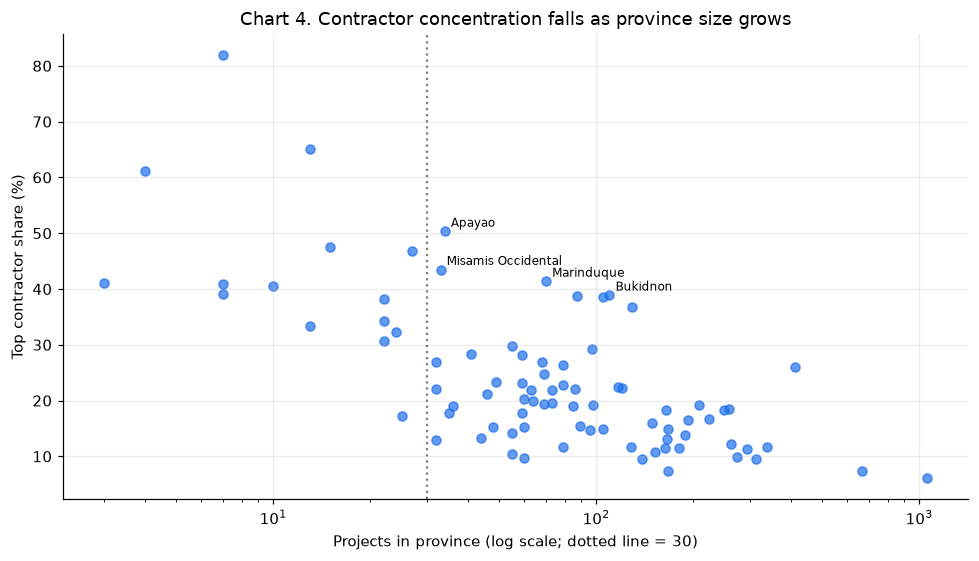

Median top-1 share, provinces under 30 projects: 0.406 | 30 or more: 0.186


In [6]:
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.scatter(prov.projects, prov.top1_share * 100, s=35, alpha=.7, color="#1F6FEB")
ax.set_xscale("log"); ax.axvline(30, color="grey", ls=":")
for p in big.head(4).index: ax.annotate(p, (prov.loc[p, "projects"], prov.loc[p, "top1_share"] * 100), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set(title="Chart 4. Contractor concentration falls as province size grows", xlabel="Projects in province (log scale; dotted line = 30)", ylabel="Top contractor share (%)")
plt.tight_layout(); plt.savefig(FIG / "chart4_concentration_vs_size.png", bbox_inches="tight"); plt.show()
print("Median top-1 share, provinces under 30 projects:", round(prov[prov.projects < 30].top1_share.median(), 3), "| 30 or more:", round(big.top1_share.median(), 3))

**Chart 4 interpretation.** Provinces with fewer projects show much higher top-contractor shares (median about 41% below 30 projects versus 19% above), a pattern that is partly mechanical because fewer projects leave fewer contractors to share the value. This is why the 30-project cut-off matters and why small provinces should not be ranked alongside large ones. The inference section tests how much of the pattern goes beyond size alone.

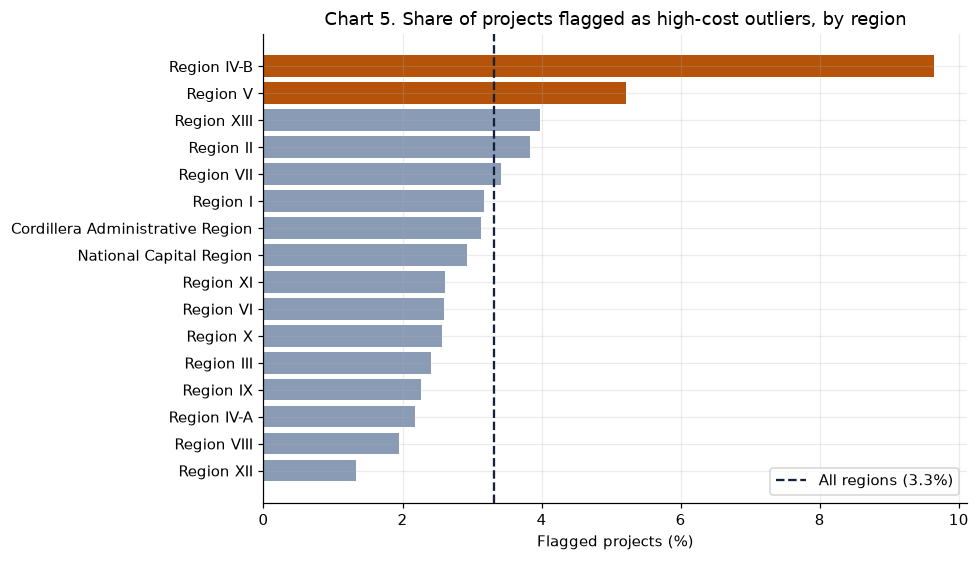

,mean,sum,count
region,,,
Region IV-B,0.096,48,498
Region V,0.052,45,863
Region XIII,0.040,12,302
Region II,0.038,24,626


In [7]:
r = df.groupby("region").is_high_cost_outlier.agg(["mean", "sum", "count"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(r.index, r["mean"] * 100, color=["#B45309" if v > df.is_high_cost_outlier.mean() * 1.5 else "#8A9BB5" for v in r["mean"]])
ax.axvline(df.is_high_cost_outlier.mean() * 100, color="#14213D", ls="--", label="All regions (3.3%)")
ax.set(title="Chart 5. Share of projects flagged as high-cost outliers, by region", xlabel="Flagged projects (%)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "chart5_outlier_rate_by_region.png", bbox_inches="tight"); plt.show()
display(r.sort_values("mean", ascending=False).head(4).round(3))

**Chart 5 interpretation.** Region IV-B has the highest flag rate at 9.6%, about three times the overall 3.3%, with Region V next at 5.2%. Within IV-B the flags are concentrated in Oriental Mindoro (24 of 139 projects) and Occidental Mindoro (16 of 105). Higher flag rates point to where costs depart most from the regional norm, but the regional z-score does not separate project type, size or site conditions, so these are places to examine first, not conclusions.

## 3. Inference with analytical caution (Week 15)

In [8]:
# Q1: Does concentration fall with province size? (Spearman rank correlation, provinces with 30+ projects)
rho, p = stats.spearmanr(big.projects, big.top1_share)
print(f"Spearman rho = {rho:.2f}, p = {p:.1e} (n = {len(big)} provinces)")

# Q2: Is observed concentration higher than a naive random baseline?
# Baseline: shuffle contractor labels across all projects in the 30+ provinces, keeping each province's project count and costs.
rng = np.random.default_rng(42); pool = df[df.province.isin(big.index)]; obs, exp = [], []
for name, g in pool.groupby("province"):
    s = g.groupby("contractor")[COST].sum(); obs.append(s.max() / s.sum())
    costs = g[COST].to_numpy(); sims = []
    for _ in range(200):
        lab = rng.permutation(pool.contractor.to_numpy())[:len(g)]
        t = pd.Series(costs).groupby(lab).sum(); sims.append(t.max() / t.sum())
    exp.append(np.mean(sims))
print(f"Median top-1 share: observed {np.median(obs):.1%} vs random baseline {np.median(exp):.1%}")

# Q3: Do outlier rates differ by region more than chance would suggest?
chi2, p3, *_ = stats.chi2_contingency(pd.crosstab(df.region, df.is_high_cost_outlier))
print(f"Chi-square test (region x outlier flag): p = {p3:.1e}")

Spearman rho = -0.44, p = 1.7e-04 (n = 69 provinces)


Median top-1 share: observed 18.6% vs random baseline 4.1%
Chi-square test (region x outlier flag): p = 1.0e-12


**Cautious interpretation.**
- **Size effect is real but not the whole story.** Concentration and province size are negatively related (Spearman ρ ≈ −0.44 among provinces with 30+ projects). Smaller provinces tend to be more concentrated, as Chart 4 suggested.
- **Observed concentration exceeds a naive baseline.** The median top contractor share (about 19%) is far above what random assignment would give (about 4%). The baseline is deliberately crude: it lets any contractor win anywhere, while in practice contractors work in specific areas for reasons such as location, capacity and procurement packaging. A gap against it is therefore expected and is **not** evidence of collusion or favouritism.
- **Outlier rates differ across regions beyond chance** (chi-square p < 0.001), which suggests the cost distributions differ by region. It does not tell us why. Project type, terrain, price levels and scale all vary by region and are not controlled for here.

**What we can and cannot say.** We can say these patterns are statistically distinguishable from a simple random model and are worth a closer look. We cannot say they reflect irregularities, because the analysis is observational, uses only completed projects, and has no information on procurement process, project specifications or site conditions. No causal claim is made.

## 4. Insights and narrative (Week 16)

### Answering the problem statement
**Can the public data reveal unusual patterns worth auditing? Yes, as leads, not conclusions.**

1. **Geographic.** Project volume and value are uneven, led by Region III (1,617 projects, about ₱98B). These are raw totals, so a population- or area-normalized view (PSA data) is needed before calling any region unusual.
2. **Financial.** 326 projects (3.3%) are high-cost relative to their region, and the flag rate is highest in Region IV-B (9.6%), driven by Oriental and Occidental Mindoro.
3. **Contractor.** No contractor dominates nationally (the top one holds about 1.5% of value), but provincial concentration is much higher in places such as Apayao (50%), Misamis Occidental (43%) and Marinduque (41%).

### Suggested review shortlist
Provinces that appear in more than one pattern (high flag rate *and* high concentration) deserve the first look. Apply the 30-project cut-off before ranking.

### Limitations
- Completed projects only, July 2022 to May 2025; ongoing or cancelled projects are not in the file.
- 638 blank municipalities and some truncated contractor names that may undercount a contractor’s total.
- The outlier flag is a regional z-score; it does not account for project type or size.
- Joint ventures (1,338 rows) are not split between partners.
